# Fourth-order propagation with ETDRK4

Compare ETDRK4 with second-order Strang splitting on a fixed periodic grid.
The transverse refractive index varies in space, so its action does not commute
with diffraction. An independent dense matrix exponential supplies the reference
solution of the spatially discretized, linear paraxial equation.

Run this notebook from the repository root or `examples/`, using a Python kernel
with this repository installed (`pip install -e .` from the repository root).
The cells use the same benchmark as `etdrk4_convergence.py`, keeping the script,
notebook, and regression tests consistent.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / 'paraxial_wave_solver').is_dir():
  root = root.parent
if not (root / 'examples' / 'etdrk4_convergence.py').is_file():
  raise RuntimeError('Run from the repository root or examples directory')
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / 'examples'))


## Problem and refinement study

The benchmark uses an 8 × 8 grid with unit transverse spacing, wavelength 1,
background index 1, and total propagation distance 2. The index perturbation is
$0.12\cos(2\pi j/8)$ and the initial field is $1+0.2\cos(2\pi j/8)$.
There is no Kerr nonlinearity or absorbing layer in this comparison.

Double the step count while holding the grid and total distance fixed.
The error is $\|u_h-u_{ref}\|_2/\|u_{ref}\|_2$ and the observed order is
$\log_2(e_h/e_{h/2})$. The benchmark enables JAX float64 precision.


In [2]:
from etdrk4_convergence import benchmark

counts, errors = benchmark()
rates = {}
print('Steps   Strang relative error   ETDRK4 relative error')
for i, count in enumerate(counts):
  print(f"{count:5d}   {errors['split_step'][i]:.8e}          "
        f"{errors['etdrk4'][i]:.8e}")
for name, expected in (('split_step', 2), ('etdrk4', 4)):
  values = np.asarray(errors[name])
  rates[name] = np.log2(values[:-1] / values[1:])
  assert np.all(np.isfinite(values)) and np.all(values > 0)
  assert np.all(np.abs(rates[name] - expected) < .2), rates[name]
  print(f'{name}: observed orders {rates[name]}')


Steps   Strang relative error   ETDRK4 relative error
    8   1.84317670e-04          7.93125370e-06
   16   4.60753881e-05          4.95748780e-07
   32   1.15185940e-05          3.09845691e-08
   64   2.87963266e-06          1.93652517e-09
split_step: observed orders [2.00012616 2.00003169 2.00000793]
etdrk4: observed orders [3.99986781 3.99998741 4.00000775]


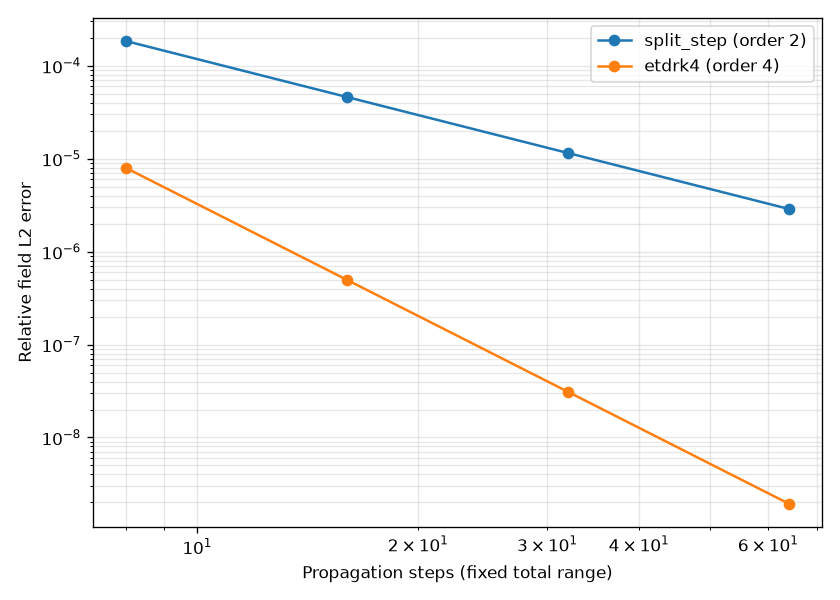

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, order in (('split_step', 2), ('etdrk4', 4)):
  ax.loglog(counts, errors[name], 'o-', label=f'{name} (order {order})')
ax.set_xlabel('Propagation steps (fixed total range)')
ax.set_ylabel('Relative field L2 error')
ax.grid(True, which='both', alpha=.3)
ax.legend()
fig.tight_layout()
plt.show()


## Interpretation and scope

Each step halving reduces the Strang error by approximately 4 and the ETDRK4
error by approximately 16. This tests longitudinal convergence for a smooth
problem at fixed spatial resolution; it is not a spatial convergence study or
a runtime comparison.

Select ETDRK4 with `SolverConfig(method='spectral', stepper='etdrk4')`.
Diffraction is integrated exponentially; medium, Kerr, and local PML terms are
explicit and can still restrict the step size. This version supports the
paraxial propagator and excludes complex coordinate stretching and dealiasing.
The unit suite additionally checks convergence with a range-dependent index,
absorption, Kerr nonlinearity, and PML against an independent ODE reference.
See [the integration guide](../docs/exponential_integrators.md) for details.
